# Inland Excess Water (IEW) Monitoring — Stage D: Teacher-Student Knowledge Distillation

Implements **§3.2 / §4.3** of the paper: self-distillation where a frozen **Teacher** (RUPNet trained on hard ground-truth labels — `rupnet.ipynb`, Stage C) supervises a fresh **Student** (identical RUPNet architecture) trained on `GDL + WFL + KL(student ‖ teacher)`. Because teacher and student share the same architecture, this is *self*-distillation (Zhang et al., 2019), which the paper reports gives the student a small but consistent edge over the teacher (Table 2).

**Pipeline position:** `A. Dataset → B. Dual-model training → C. Backbone selection (rupnet.ipynb) → D. Knowledge Distillation (this notebook) → E. SplitClass Segmentation → F. Temporal Gap-Filling`

**Prerequisite:** run `rupnet.ipynb` first — it produces `outputs/checkpoints/rupnet_best.pt`, loaded below as the frozen teacher.

Flow: imports → data pipeline → losses (incl. KD loss) → model → load frozen teacher → train student → loss curves → Teacher-vs-Student evaluation (Table 2 layout) → prediction visualization.

## 1. Imports and Setup

In [1]:
import os
import sys
import glob
import yaml
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import rasterio
from rasterio.windows import Window
from pathlib import Path
from typing import List, Dict, Tuple

torch.manual_seed(0)
np.random.seed(0)

print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


PyTorch 2.5.1+cu121 | CUDA available: True


## 2. Data Pipeline
Same self-contained GeoTIFF I/O + `Dataset` as the Stage-C notebooks.

In [2]:
# --- Raster I/O helpers -----------------------------------------------------
def read_s2(path: str) -> np.ndarray:
    """Read a Sentinel-2 GeoTIFF -> (11, H, W) float32, scaled to reflectance [0, ~1.7]."""
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
        data /= 10000.0  # S2 BOA reflectance is stored scaled by 10000
        return data

def read_s1(path: str) -> np.ndarray:
    """Read a Sentinel-1 GeoTIFF -> (3, H, W) float32: VV, VH, VV/VH ratio (dB)."""
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)

def read_gt(path: str) -> np.ndarray:
    """Read a ground-truth GeoTIFF -> (H, W) int class map."""
    with rasterio.open(path) as src:
        return src.read(1)


def get_scene_files(dataset_root: str, split: str) -> List[Dict[str, str]]:
    """Find and align S1, S2, GT, GT_0_8 files for a split ('Train'/'Test'), keyed off S2."""
    root = Path(dataset_root)
    split_dir = root / "tifs" / split

    s1_dir = split_dir / "S1"
    s2_dir = split_dir / "S2"
    gt_dir = split_dir / "GT"
    gt08_dir = split_dir / "GT_0_8"

    s2_files = sorted(split_dir.joinpath("S2").glob("*.tif"))

    aligned = []
    for s2_file in s2_files:
        name = s2_file.name
        s1_path = s1_dir / name
        gt_path = gt_dir / name
        gt08_path = gt08_dir / name

        if not s1_path.exists():
            raise FileNotFoundError(f"Missing S1 file: {s1_path}")
        if not gt_path.exists():
            raise FileNotFoundError(f"Missing GT file: {gt_path}")
        if not gt08_path.exists():
            raise FileNotFoundError(f"Missing GT_0_8 file: {gt08_path}")

        aligned.append({
            "name": s2_file.stem,
            "S1": str(s1_path),
            "S2": str(s2_file),
            "GT": str(gt_path),
            "GT_0_8": str(gt08_path),
        })
    return aligned

print("Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files")


Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files


In [3]:
# --- PyTorch Dataset ---------------------------------------------------------
# Per-channel statistics computed over the training split.
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598, 0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598, 0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)

S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)


class FloodPatchDataset(Dataset):
    """Sliding-window dataset over aligned S1/S2/GT scenes. Reads windows directly from
    disk via rasterio (or caches full scenes in memory), standardizes per-channel, and
    optionally applies flip/rotation augmentation.
    """

    def __init__(
        self,
        dataset_root: str,
        split: str,
        patch_size: int = 64,
        stride: int = 64,
        augment: bool = False,
        cache_in_memory: bool = False,
        load_s1: bool = True,
    ):
        self.dataset_root = dataset_root
        self.split = split
        self.patch_size = patch_size
        self.stride = stride
        self.augment = augment
        self.cache_in_memory = cache_in_memory
        self.load_s1 = load_s1

        self.scenes = get_scene_files(dataset_root, split)

        self.s2_cache, self.s1_cache, self.gt_cache = {}, {}, {}
        self.patches = []

        print(f"Initializing {split} dataset (cache_in_memory={cache_in_memory}, load_s1={load_s1})...")

        for scene_idx, scene in enumerate(self.scenes):
            with rasterio.open(scene["S2"]) as s2_src:
                H, W = s2_src.height, s2_src.width

            if cache_in_memory:
                with rasterio.open(scene["S2"]) as s2_src:
                    s2_img = s2_src.read().astype(np.float32)
                    s2_img /= 10000.0
                    self.s2_cache[scene_idx] = s2_img
                if load_s1:
                    with rasterio.open(scene["S1"]) as s1_src:
                        self.s1_cache[scene_idx] = s1_src.read().astype(np.float32)
                with rasterio.open(scene["GT_0_8"]) as gt_src:
                    self.gt_cache[scene_idx] = gt_src.read(1).astype(np.int64)
            # else: no persistent file handles are opened here - see __getitem__, which
            # opens+reads+closes per access. This keeps the Dataset free of unpicklable
            # state (required for num_workers > 0, since DataLoader workers get a pickled
            # copy of the Dataset) and avoids GDAL's internal per-handle cache growing
            # unbounded over a long-running, many-epoch loop that reuses the same handle.

            for y in range(0, H - patch_size + 1, stride):
                for x in range(0, W - patch_size + 1, stride):
                    self.patches.append({"scene_idx": scene_idx, "y": y, "x": x})

        print(f"Loaded {split} dataset with {len(self.patches)} total patches from {len(self.scenes)} scenes.")

    def __len__(self) -> int:
        return len(self.patches)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        info = self.patches[idx]
        scene_idx, y, x = info["scene_idx"], info["y"], info["x"]

        if self.cache_in_memory:
            s2_data = self.s2_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            if self.load_s1:
                s1_data = self.s1_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            gt_data = self.gt_cache[scene_idx][y:y + self.patch_size, x:x + self.patch_size].copy()
        else:
            scene = self.scenes[scene_idx]
            window = Window(x, y, self.patch_size, self.patch_size)
            with rasterio.open(scene["S2"]) as s2_src:
                s2_data = s2_src.read(window=window).astype(np.float32)
            s2_data /= 10000.0
            if self.load_s1:
                with rasterio.open(scene["S1"]) as s1_src:
                    s1_data = s1_src.read(window=window).astype(np.float32)
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            with rasterio.open(scene["GT_0_8"]) as gt_src:
                gt_data = gt_src.read(1, window=window).astype(np.int64)

        for c in range(11):
            s2_data[c] = (s2_data[c] - S2_MEAN[c]) / S2_STD[c]
        if self.load_s1:
            for c in range(3):
                s1_data[c] = (s1_data[c] - S1_MEAN[c]) / S1_STD[c]

        if self.augment:
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=2).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=2).copy()
                gt_data = np.flip(gt_data, axis=1).copy()
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=1).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=1).copy()
                gt_data = np.flip(gt_data, axis=0).copy()
            rot_k = np.random.randint(0, 4)
            if rot_k > 0:
                s2_data = np.rot90(s2_data, k=rot_k, axes=(1, 2)).copy()
                if self.load_s1:
                    s1_data = np.rot90(s1_data, k=rot_k, axes=(1, 2)).copy()
                gt_data = np.rot90(gt_data, k=rot_k, axes=(0, 1)).copy()

        return torch.from_numpy(s2_data), torch.from_numpy(s1_data), torch.from_numpy(gt_data)


print("FloodPatchDataset ready")


FloodPatchDataset ready


In [4]:
def stretch_rgb(rgb: np.ndarray, low: float = 2.0, high: float = 98.0) -> np.ndarray:
    """Per-channel percentile contrast stretch for a true-color composite (see rupnet.ipynb
    diagnosis note - a fixed divisor washes scenes out or leaves them too dark)."""
    out = np.empty_like(rgb, dtype=np.float32)
    for c in range(rgb.shape[-1]):
        lo, hi = np.percentile(rgb[..., c], [low, high])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


print("stretch_rgb ready")


stretch_rgb ready


## 3. Dataset Visualization

Displaying scene: BNPI_20210310


C:\Users\prajw\AppData\Local\Temp\ipykernel_54516\4264571949.py:17: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  return src.read(1)


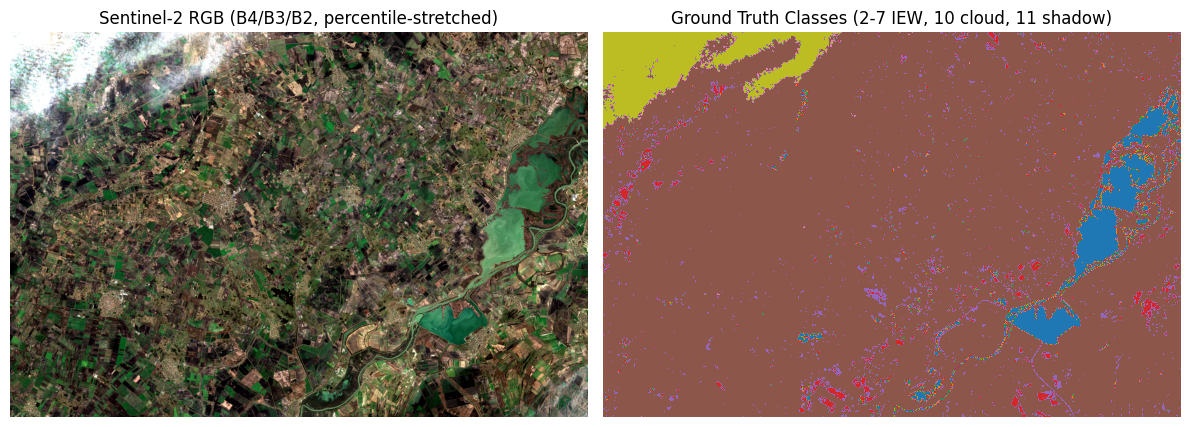

In [5]:
# Load configuration
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)
dataset_root = config["dataset_root"]

train_scenes = get_scene_files(dataset_root, "Train")
sample_scene = train_scenes[1]  # BNPI_20210310
print(f"Displaying scene: {sample_scene['name']}")

s2_img = read_s2(sample_scene["S2"])
gt_img = read_gt(sample_scene["GT"])
rgb = stretch_rgb(np.stack([s2_img[3], s2_img[2], s2_img[1]], axis=-1))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB (B4/B3/B2, percentile-stretched)")
axes[0].axis("off")
axes[1].imshow(gt_img, cmap="tab10", vmin=2, vmax=11)
axes[1].set_title("Ground Truth Classes (2-7 IEW, 10 cloud, 11 shadow)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 4. Loss Functions
GDL + WFL (identical to Stage C) plus the KD-specific KL-divergence term used only for the student.

In [6]:
class GeneralizedDiceLoss(nn.Module):
    """Class-weighted Generalized Dice Loss (Sudre et al., 2017), with an ignore_index
    to mask out cloud/shadow pixels (label >= ignore_index) from the loss."""

    def __init__(self, ignore_index: int = 6, num_classes: int = 6, eps: float = 1e-6):
        super().__init__()
        self.ignore_index = ignore_index
        self.num_classes = num_classes
        self.eps = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)

        valid_mask = (targets < self.ignore_index).unsqueeze(1)
        probs = probs * valid_mask

        targets_clamped = torch.clamp(targets, 0, self.num_classes - 1)
        targets_onehot = F.one_hot(targets_clamped, num_classes=self.num_classes)
        targets_onehot = targets_onehot.permute(0, 3, 1, 2).float()
        targets_onehot = targets_onehot * valid_mask

        intersection = torch.sum(probs * targets_onehot, dim=(0, 2, 3))
        union = torch.sum(probs + targets_onehot, dim=(0, 2, 3))

        class_pixel_counts = torch.sum(targets_onehot, dim=(0, 2, 3))
        weights = 1.0 / (class_pixel_counts ** 2 + self.eps)
        weights = weights / (torch.sum(weights) + self.eps)

        numerator = 2.0 * torch.sum(weights * intersection)
        denominator = torch.sum(weights * union)

        return 1.0 - (numerator + self.eps) / (denominator + self.eps)


class WeightedFocalLoss(nn.Module):
    """Class-weighted Focal Loss (Lin et al., 2017) with an ignore_index."""

    def __init__(self, alpha: torch.Tensor = None, gamma: float = 2.0, ignore_index: int = 6):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        C = logits.size(1)
        logits_flat = logits.permute(0, 2, 3, 1).contiguous().view(-1, C)
        targets_flat = targets.view(-1)

        valid_mask = targets_flat < self.ignore_index
        if not valid_mask.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        logits_valid = logits_flat[valid_mask]
        targets_valid = targets_flat[valid_mask]

        log_probs = F.log_softmax(logits_valid, dim=1)
        log_probs_target = log_probs[torch.arange(len(targets_valid)), targets_valid]
        probs_target = torch.exp(log_probs_target)

        focal_weight = (1.0 - probs_target) ** self.gamma
        loss = -focal_weight * log_probs_target

        if self.alpha is not None:
            self.alpha = self.alpha.to(logits.device)
            loss = loss * self.alpha[targets_valid]

        return loss.mean()


print("GeneralizedDiceLoss, WeightedFocalLoss ready")


GeneralizedDiceLoss, WeightedFocalLoss ready


In [7]:
class KDLoss(nn.Module):
    """KL-divergence(student softened softmax || teacher softened softmax), restricted to
    valid (non-cloud/shadow) pixels. This is the third loss term added for the *student*
    only (§3.2/§4.3: "GDL + WFL + KL(student vs teacher)") - self-distillation, since
    teacher and student share the same RUPNet architecture (Zhang et al., 2019).

    Temperature T and the KD loss weight lambda_kd are NOT specified anywhere in the paper
    (unlike batch size/LR/epochs, which ARE stated in §4.1 and used verbatim below) -
    defaults here (T=2.0, lambda_kd=1.0, the standard Hinton et al. 2015 starting point) are
    a documented assumption. Treat TEMPERATURE/LAMBDA_KD as knobs to sweep and report.
    """

    def __init__(self, temperature: float = 2.0, ignore_index: int = 6):
        super().__init__()
        self.T = temperature
        self.ignore_index = ignore_index

    def forward(self, student_logits: torch.Tensor, teacher_logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        valid_mask = (targets < self.ignore_index).unsqueeze(1).float()

        student_log_probs = F.log_softmax(student_logits / self.T, dim=1)
        teacher_probs = F.softmax(teacher_logits / self.T, dim=1)

        kl = teacher_probs * (torch.log(teacher_probs + 1e-10) - student_log_probs)
        kl = kl * valid_mask
        n_valid = valid_mask.sum().clamp_min(1.0)
        return (kl.sum() * (self.T ** 2)) / n_valid


print("KDLoss ready")


KDLoss ready


## 5. Model Architecture — RUPNet (shared by Teacher and Student)

In [8]:
class Conv2D(nn.Module):
    def __init__(self, in_c, out_c, kernel_size=3, padding=1, stride=1, dilation=1, bias=False, act=True):
        super().__init__()
        self.act = act
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size, stride=stride, padding=padding, dilation=dilation, bias=bias),
            nn.BatchNorm2d(out_c),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        if self.act:
            x = self.relu(x)
        return x


class ResidualBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
        )
        self.shortcut = nn.Sequential()
        if in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=1, stride=1, bias=False),
                nn.BatchNorm2d(out_c),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.conv(x) + self.shortcut(x))


class DecoderBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
        self.res = ResidualBlock(in_c + out_c, out_c)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.res(x)


class UpBlock(nn.Module):
    def __init__(self, in_c, out_c, scale):
        super().__init__()
        self.up = nn.Upsample(scale_factor=scale, mode="bilinear", align_corners=True)
        self.res = ResidualBlock(in_c, out_c)

    def forward(self, x):
        return self.res(self.up(x))


class RUPNet(nn.Module):
    """RUPNet (Tomar, Bagci & Jha, 2023) - the paper's winning backbone (Table 1,
    F1 = 81.19%) and its knowledge-distillation teacher/student architecture (~2.05M params
    at in_channels=11; scales down automatically for fewer input channels, e.g. the 3-channel
    Radar_Model)."""

    def __init__(self, in_channels: int = 11, num_classes: int = 6):
        super().__init__()

        self.init_conv = Conv2D(in_channels, 32, kernel_size=3, padding=1)

        self.enc1_1 = ResidualBlock(32, 64)
        self.down1 = nn.MaxPool2d(2)
        self.enc1_2 = ResidualBlock(64, 64)
        self.down2 = nn.MaxPool2d(2)  # scale: H/4

        self.enc2 = ResidualBlock(64, 128)
        self.down3 = nn.MaxPool2d(2)  # scale: H/8

        self.enc3 = ResidualBlock(128, 256)
        self.down4 = nn.MaxPool2d(2)  # scale: H/16

        self.c1 = Conv2D(64, 64, kernel_size=1, padding=0)
        self.c2 = Conv2D(128, 64, kernel_size=1, padding=0)
        self.c3 = Conv2D(256, 64, kernel_size=1, padding=0)

        self.d1 = DecoderBlock(64, 64)
        self.d2 = DecoderBlock(64, 64)

        self.d3 = UpBlock(64, 64, scale=4)
        self.u1 = UpBlock(64, 64, scale=4)
        self.u2 = UpBlock(64, 64, scale=8)
        self.u3 = UpBlock(64, 64, scale=16)

        self.fusion = ResidualBlock(256, 64)
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, inputs):
        x = self.init_conv(inputs)

        e1 = self.enc1_1(x)
        e1 = self.down1(e1)
        e1 = self.enc1_2(e1)
        e1 = self.down2(e1)  # (B, 64, H/4, W/4)

        e2 = self.enc2(e1)
        e2 = self.down3(e2)  # (B, 128, H/8, W/8)

        e3 = self.enc3(e2)
        e3 = self.down4(e3)  # (B, 256, H/16, W/16)

        c1 = self.c1(e1)
        c2 = self.c2(e2)
        c3 = self.c3(e3)

        d1 = self.d1(c3, c2)  # (B, 64, H/8, W/8)
        d2 = self.d2(d1, c1)  # (B, 64, H/4, W/4)

        d3 = self.d3(d2)  # (B, 64, H, W)
        u1 = self.u1(c1)  # (B, 64, H, W)
        u2 = self.u2(c2)  # (B, 64, H, W)
        u3 = self.u3(c3)  # (B, 64, H, W)

        fused = torch.cat([d3, u1, u2, u3], dim=1)  # (B, 256, H, W)
        fused = self.fusion(fused)  # (B, 64, H, W)

        return self.outc(fused)


print("RUPNet ready")


RUPNet ready


## 6. Dataset & Dataloader Setup
Full non-overlapping patch grid (100% spatial coverage, ~52k patches) built once; each epoch trains on a fresh random subset of it (§9) rather than the whole grid or a shrunk static grid - see `rupnet.ipynb` §6 for the full reasoning, including two rejected alternatives.

In [9]:
TRAIN_PIXEL_COUNTS = [7674525, 651441, 900550, 4493763, 3450129, 195012790]
counts = np.array(TRAIN_PIXEL_COUNTS, dtype=np.float32)
total = counts.sum()
weights = total / (len(counts) * counts)
weights = weights / weights.mean()
class_weights = torch.from_numpy(weights).float()
print(f"Class weights: {class_weights.tolist()}")

BATCH_SIZE = 32  # paper §4.1

train_dataset = FloodPatchDataset(
    dataset_root=dataset_root, split="Train", patch_size=config["patch_size"],
    stride=config["patch_size"], augment=True, cache_in_memory=False, load_s1=False,
)
test_dataset = FloodPatchDataset(
    dataset_root=dataset_root, split="Test", patch_size=config["patch_size"],
    stride=512, augment=False, cache_in_memory=False, load_s1=False,
)

print(f"Full train patch grid: {len(train_dataset):,} patches (100% spatial coverage)")
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


Class weights: [0.23739364743232727, 2.7966976165771484, 2.023078680038452, 0.40542489290237427, 0.5280624032020569, 0.009342379868030548]
Initializing Train dataset (cache_in_memory=False, load_s1=False)...
Loaded Train dataset with 52353 total patches from 14 scenes.
Initializing Test dataset (cache_in_memory=False, load_s1=False)...
Loaded Test dataset with 558 total patches from 9 scenes.
Full train patch grid: 52,353 patches (100% spatial coverage)


## 7. Load the Frozen Teacher
The Teacher is RUPNet trained directly on hard GT labels — exactly the model produced by `rupnet.ipynb`. It is frozen (`requires_grad_(False)`, `eval()` mode throughout) and only used to generate soft targets.

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

TEACHER_CKPT_PATH = "outputs/checkpoints/rupnet_best.pt"
if not os.path.exists(TEACHER_CKPT_PATH):
    raise FileNotFoundError(
        f"{TEACHER_CKPT_PATH} not found - run rupnet.ipynb first to train the teacher "
        "(Stage C must complete before Stage D can distill from it)."
    )

teacher = RUPNet(in_channels=11, num_classes=6).to(device)
teacher_ckpt = torch.load(TEACHER_CKPT_PATH, map_location=device)
teacher.load_state_dict(teacher_ckpt["model_state_dict"])
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

print(f"Loaded frozen teacher from {TEACHER_CKPT_PATH} "
      f"(epoch {teacher_ckpt['epoch']}, val_loss {teacher_ckpt['val_loss']:.4f})")


Using device: cuda
Loaded frozen teacher from outputs/checkpoints/rupnet_best.pt (epoch 48, val_loss 0.7438)


C:\Users\prajw\AppData\Local\Temp\ipykernel_54516\2139992080.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  teacher_ckpt = torch.load(TEACHER_CKPT_PATH, map_location=d

## 8. Student Setup
A fresh RUPNet (same architecture, new random init). Optimizer/LR/epochs follow the paper's §4.1 recipe verbatim (`Adam`, LR `1e-4`, `100` epochs, batch `32`) — no scheduler, since the paper doesn't extend one to the KD stage either. TEMPERATURE/LAMBDA_KD are documented assumptions (see KDLoss docstring).

In [11]:
student = RUPNet(in_channels=11, num_classes=6).to(device)

# Paper §4.1: "batch size of 32, trained over 100 epochs, and a learning rate of 10^-4" -
# used verbatim here too. TEMPERATURE/LAMBDA_KD are NOT paper-specified (see §4 KDLoss note).
EPOCHS = 100
LEARNING_RATE = 1e-4
TEMPERATURE = 2.0   # KD softening temperature - assumption
LAMBDA_KD = 1.0     # KD loss weight - assumption

criterion_gdl = GeneralizedDiceLoss(ignore_index=6, num_classes=6)
criterion_wfl = WeightedFocalLoss(alpha=class_weights, gamma=2.0, ignore_index=6)
criterion_kd = KDLoss(temperature=TEMPERATURE, ignore_index=6)

optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)


## 9. Training Loop
Student loss = `GDL(hard) + WFL(hard) + LAMBDA_KD * KL(student ‖ teacher)`. Teacher stays frozen throughout — no gradient flows into it. Constant LR (no schedule), matching the paper's stated recipe.

In [ ]:
epochs = EPOCHS
SAMPLES_PER_EPOCH = 13000  # ~1/4 of the full grid per epoch, redrawn randomly every epoch
                            # so there is no permanent spatial blind spot (see §6)
epoch_rng = np.random.default_rng(0)

history = {"train_loss": [], "val_loss": [], "train_gdl": [], "train_wfl": [], "train_kd": []}
best_val_loss = float("inf")

for epoch in range(1, epochs + 1):
    student.train()
    epoch_loss = epoch_gdl = epoch_wfl = epoch_kd = 0.0

    # Fresh random subset of the full patch grid this epoch - see §6/§9 notes.
    subset_idx = epoch_rng.choice(len(train_dataset), size=min(SAMPLES_PER_EPOCH, len(train_dataset)), replace=False)
    train_loader = DataLoader(Subset(train_dataset, subset_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    for s2_patches, _, gt_patches in train_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.to(device)

        optimizer.zero_grad()
        student_logits = student(s2_patches)
        with torch.no_grad():
            teacher_logits = teacher(s2_patches)

        loss_gdl = criterion_gdl(student_logits, gt_patches)
        loss_wfl = criterion_wfl(student_logits, gt_patches)
        loss_kd = criterion_kd(student_logits, teacher_logits, gt_patches)
        loss = loss_gdl + loss_wfl + LAMBDA_KD * loss_kd

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_gdl += loss_gdl.item()
        epoch_wfl += loss_wfl.item()
        epoch_kd += loss_kd.item()

    n_batches = len(train_loader)
    avg_train_loss, avg_train_gdl = epoch_loss / n_batches, epoch_gdl / n_batches
    avg_train_wfl, avg_train_kd = epoch_wfl / n_batches, epoch_kd / n_batches

    student.eval()
    val_loss = 0.0
    with torch.no_grad():
        for s2_patches, _, gt_patches in test_loader:
            s2_patches = s2_patches.to(device)
            gt_patches = gt_patches.to(device)
            student_logits = student(s2_patches)
            teacher_logits = teacher(s2_patches)
            loss_gdl = criterion_gdl(student_logits, gt_patches)
            loss_wfl = criterion_wfl(student_logits, gt_patches)
            loss_kd = criterion_kd(student_logits, teacher_logits, gt_patches)
            val_loss += (loss_gdl + loss_wfl + LAMBDA_KD * loss_kd).item()

    avg_val_loss = val_loss / len(test_loader)

    history["train_loss"].append(avg_train_loss)
    history["train_gdl"].append(avg_train_gdl)
    history["train_wfl"].append(avg_train_wfl)
    history["train_kd"].append(avg_train_kd)
    history["val_loss"].append(avg_val_loss)

    is_best = avg_val_loss < best_val_loss
    if is_best:
        best_val_loss = avg_val_loss
        torch.save({"model_state_dict": student.state_dict(), "epoch": epoch, "val_loss": avg_val_loss},
                   "outputs/checkpoints/rupnet_student_best.pt")

    flag = " *" if is_best else ""
    print(f"Epoch {epoch}/{epochs} - Train Loss: {avg_train_loss:.4f} "
          f"(GDL: {avg_train_gdl:.4f}, WFL: {avg_train_wfl:.4f}, KD: {avg_train_kd:.4f}) "
          f"| Val Loss: {avg_val_loss:.4f}{flag}")

print(f"Training complete! Best val loss: {best_val_loss:.4f} -> outputs/checkpoints/rupnet_student_best.pt")


C:\Users\prajw\AppData\Roaming\Python\Python312\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
C:\Users\prajw\AppData\Local\Temp\ipykernel_54516\3759900618.py:93: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  gt_data = gt_src.read(1, window=window).astype(np.int64)


Epoch 1/100 - Train Loss: 3.3150 (GDL: 0.9415, WFL: 0.0500, KD: 2.3236) | Val Loss: 2.0661 *
Epoch 2/100 - Train Loss: 1.6009 (GDL: 0.8093, WFL: 0.0511, KD: 0.7405) | Val Loss: 1.2969 *
Epoch 3/100 - Train Loss: 1.1766 (GDL: 0.7562, WFL: 0.0563, KD: 0.3640) | Val Loss: 1.0708 *
Epoch 4/100 - Train Loss: 1.0335 (GDL: 0.7270, WFL: 0.0558, KD: 0.2507) | Val Loss: 1.0084 *
Epoch 5/100 - Train Loss: 0.9702 (GDL: 0.7154, WFL: 0.0556, KD: 0.1991) | Val Loss: 0.9648 *
Epoch 6/100 - Train Loss: 0.9250 (GDL: 0.7045, WFL: 0.0516, KD: 0.1689) | Val Loss: 0.9542 *
Epoch 7/100 - Train Loss: 0.8965 (GDL: 0.6937, WFL: 0.0520, KD: 0.1508) | Val Loss: 0.9309 *
Epoch 8/100 - Train Loss: 0.8726 (GDL: 0.6856, WFL: 0.0507, KD: 0.1363) | Val Loss: 1.0132
Epoch 9/100 - Train Loss: 0.8453 (GDL: 0.6733, WFL: 0.0484, KD: 0.1236) | Val Loss: 0.8724 *
Epoch 10/100 - Train Loss: 0.8294 (GDL: 0.6654, WFL: 0.0480, KD: 0.1159) | Val Loss: 0.9613
Epoch 11/100 - Train Loss: 0.8215 (GDL: 0.6609, WFL: 0.0474, KD: 0.1133) 

## 10. Loss Curves

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train Total Loss")
plt.plot(history["train_gdl"], label="Train GDL")
plt.plot(history["train_wfl"], label="Train WFL")
plt.plot(history["train_kd"], label="Train KD (KL)")
plt.plot(history["val_loss"], label="Val Total Loss", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Student Loss Curves (GDL + WFL + KD)")
plt.legend()
plt.grid(True)
plt.show()


## 11. Evaluation — Teacher vs. Student (Table 2 layout)
Both models evaluated on the identical full, non-overlapping test set. The paper's Table 2 "All" row is pixel-weighted across **all 6 classes** (2-7) — unlike Table 1, it does not exclude the majority class — so that is the metric reproduced here.

In [ ]:
class_names = [
    "Open surface water (2)",
    "Soil seriously affected (3)",
    "Soil moderately affected (4)",
    "Soil slightly affected (5)",
    "Vegetation affected (6)",
    "Not affected areas (7)",
]


def evaluate_model(model, loader):
    model.eval()
    tp = np.zeros(6, dtype=np.int64)
    fp = np.zeros(6, dtype=np.int64)
    fn = np.zeros(6, dtype=np.int64)
    class_pixel_counts = np.zeros(6, dtype=np.int64)

    with torch.no_grad():
        for s2_patches, _, gt_patches in loader:
            s2_patches = s2_patches.to(device)
            gt_patches = gt_patches.numpy()
            logits = model(s2_patches)
            preds = torch.argmax(logits, dim=1).cpu().numpy()

            for b in range(preds.shape[0]):
                pred_b, gt_b = preds[b], gt_patches[b]
                valid_mask = gt_b < 6
                for c in range(6):
                    pred_c = (pred_b == c) & valid_mask
                    gt_c = (gt_b == c) & valid_mask
                    tp[c] += np.sum(pred_c & gt_c)
                    fp[c] += np.sum(pred_c & ~gt_c)
                    fn[c] += np.sum(~pred_c & gt_c)
                    class_pixel_counts[c] += np.sum(gt_c)

    pr = tp / (tp + fp + 1e-10)
    rc = tp / (tp + fn + 1e-10)
    f1 = 2 * pr * rc / (pr + rc + 1e-10)
    w = class_pixel_counts / class_pixel_counts.sum()
    overall = {"pr": float(np.sum(pr * w)), "rc": float(np.sum(rc * w)), "f1": float(np.sum(f1 * w))}
    return {"pr": pr, "rc": rc, "f1": f1, "overall": overall, "pixel_counts": class_pixel_counts}


eval_dataset = FloodPatchDataset(
    dataset_root=dataset_root, split="Test", patch_size=config["patch_size"],
    stride=config["patch_size"], augment=False, cache_in_memory=False, load_s1=False,
)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

teacher_metrics = evaluate_model(teacher, eval_loader)
student_metrics = evaluate_model(student, eval_loader)

print("\n" + "=" * 78)
print(f"{'Class':<32}{'Teacher F1':<14}{'Student F1':<14}{'Delta':<10}")
print("=" * 78)
for i, name in enumerate(class_names):
    t, s = teacher_metrics["f1"][i] * 100, student_metrics["f1"][i] * 100
    print(f"{name:<32}{t:<14.2f}{s:<14.2f}{s - t:+.2f}")
print("-" * 78)
to, so = teacher_metrics["overall"]["f1"] * 100, student_metrics["overall"]["f1"] * 100
print(f"{'ALL (pixel-weighted, classes 2-7)':<32}{to:<14.2f}{so:<14.2f}{so - to:+.2f}")
print("=" * 78)
print(f"\nTeacher  Pr={teacher_metrics['overall']['pr']*100:.2f}  Rc={teacher_metrics['overall']['rc']*100:.2f}  F1={teacher_metrics['overall']['f1']*100:.2f}")
print(f"Student  Pr={student_metrics['overall']['pr']*100:.2f}  Rc={student_metrics['overall']['rc']*100:.2f}  F1={student_metrics['overall']['f1']*100:.2f}")
print("\nPaper (Table 2, All row, top-1): Teacher Pr/Rc/F1 = 0.98/0.96/0.97   Student = 0.98/0.97/0.98")
if so > to:
    print("\n-> Student outperforms Teacher: consistent with the paper's self-distillation claim.")
else:
    print("\n-> Student did NOT outperform Teacher this run: a legitimate finding, not necessarily a bug - "
          "self-distillation gains are known to be inconsistent across datasets/architectures. Consider "
          "sweeping TEMPERATURE / LAMBDA_KD / EPOCHS before concluding it doesn't help here.")


## 12. Visualizing Predictions — GT vs. Teacher vs. Student
Patches chosen by GT class diversity (see `rupnet.ipynb` §11 for why), not arbitrary fixed indices.

In [ ]:
def patch_class_diversity(idx):
    _, _, gt = eval_dataset[idx]
    gt_np = gt.numpy()
    valid = gt_np[gt_np < 6]
    return len(np.unique(valid)) if valid.size else 0

scan_indices = range(0, len(eval_dataset), 37)
diversity_scores = sorted(((idx, patch_class_diversity(idx)) for idx in scan_indices), key=lambda t: t[1], reverse=True)
chosen = [idx for idx, _ in diversity_scores[:3]]
print(f"Chosen patches (by GT class diversity): {[(idx, s) for idx, s in diversity_scores[:3]]}")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, patch_idx in enumerate(chosen):
    s2, _, gt = eval_dataset[patch_idx]
    s2_in = s2.unsqueeze(0).to(device)
    with torch.no_grad():
        teacher_pred = torch.argmax(teacher(s2_in), dim=1).squeeze(0).cpu().numpy()
        student_pred = torch.argmax(student(s2_in), dim=1).squeeze(0).cpu().numpy()

    s2_np = s2.numpy()
    rgb = np.stack([s2_np[3], s2_np[2], s2_np[1]], axis=-1)
    rgb = rgb * S2_STD[[3, 2, 1]] + S2_MEAN[[3, 2, 1]]
    rgb = stretch_rgb(rgb)

    axes[i, 0].imshow(rgb); axes[i, 0].set_title("Input RGB"); axes[i, 0].axis("off")
    axes[i, 1].imshow(gt.numpy(), cmap="tab10", vmin=0, vmax=5); axes[i, 1].set_title("GT Mask"); axes[i, 1].axis("off")
    axes[i, 2].imshow(teacher_pred, cmap="tab10", vmin=0, vmax=5); axes[i, 2].set_title("Teacher Prediction"); axes[i, 2].axis("off")
    axes[i, 3].imshow(student_pred, cmap="tab10", vmin=0, vmax=5); axes[i, 3].set_title("Student Prediction"); axes[i, 3].axis("off")

plt.tight_layout()
plt.show()


## 13. Summary — fill in after running

- **Teacher F1 (All):** ___  **Student F1 (All):** ___  → student better? ___
- **Classes where distillation helped most:** ___ (the paper claims classes 3-6 benefit most, since the teacher's soft labels carry information about visually-similar neighboring severity classes that hard one-hot labels discard)
- **TEMPERATURE / LAMBDA_KD used:** 2.0 / 1.0 (defaults — record here if you swept other values)
- **Checkpoint produced:** `outputs/checkpoints/rupnet_student_best.pt` — this is the model `05_splitclass_segmentation.ipynb` expects.